In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tasfiatahsinannita/crop-yield-sample/bangladesh_crop_yield_synthetic_1000.csv


In [2]:
!pip install -q "jaxtyping<0.3" "typeguard<3"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydata-profiling 4.18.4 requires typeguard<5,>=4, but you have typeguard 2.13.3 which is incompatible.
inflect 7.5.0 requires typeguard>=4.0.1, but you have typeguard 2.13.3 which is incompatible.


In [3]:
import jaxtyping
import typeguard

print("jaxtyping:", jaxtyping.__version__)
print("TabFM dependencies imported successfully")

jaxtyping: 0.2.38
TabFM dependencies imported successfully


1. PREPARING PACKAGES
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 16.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 12.0 MB/s  0:00:00



Cloning into '/kaggle/working/tabfm'...


Obtaining file:///kaggle/working/tabfm
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for tabfm (pyproject.toml): started
  Building editable for tabfm (pyproject.toml): finished with status 'done'
  Created wheel for tabfm: filename=tabfm-1.0.1-py3-none-any.whl size=7920 sha256=08d58365bb1c2155c918177db0403ca5678ac1a3424e6c73c91d5c03298ea953
  Stored in directory: /tmp/pip-ephem-wheel-cache-zkybiv4w/wheels/3a/90/9a/cb38526ed2ff6bbff66cf7d2ae4684f9756f5fefe98444f8af
Successfully built tabfm

PyTorch: 2.11.0+cu128
CUDA availab

Loading pretrained TabFM regression checkpoint...
The first run may download several GB of model weights.


config.json:   0%|          | 0.00/97.0 [00:00<?, ?B/s]

...

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]


TabPFN metrics
MSE : 20.982770
RMSE: 4.580695 tonnes/ha
MAE : 1.780799 tonnes/ha
R²  : 0.976642

TABPFN SUCCESS

6. MODEL COMPARISON


,Model,MSE,RMSE,MAE,R2
0,TabFM,7.113203,2.667059,1.209543,0.992082
1,TabPFN,20.982770,4.580695,1.780799,0.976642



Saved: /kaggle/working/model_comparison_results.csv
Saved: /kaggle/working/crop_yield_predictions.csv


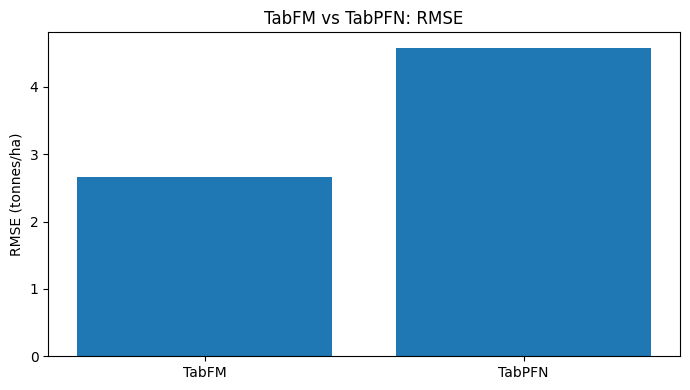

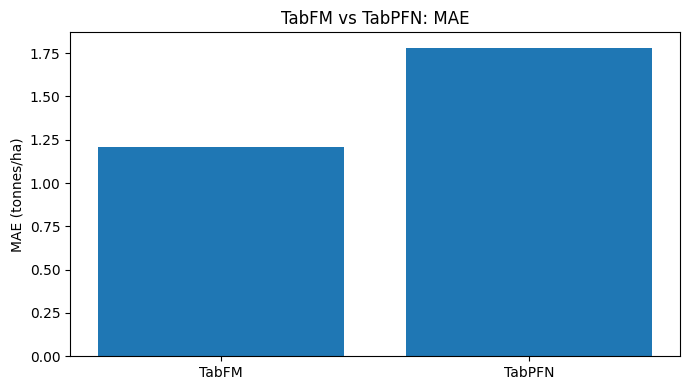

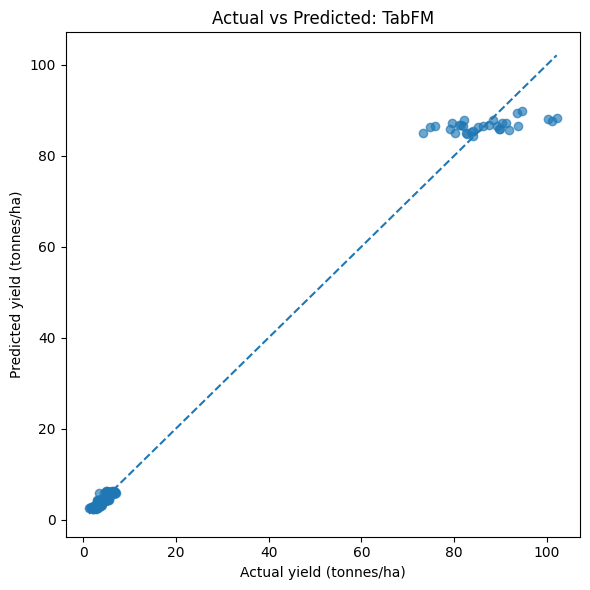

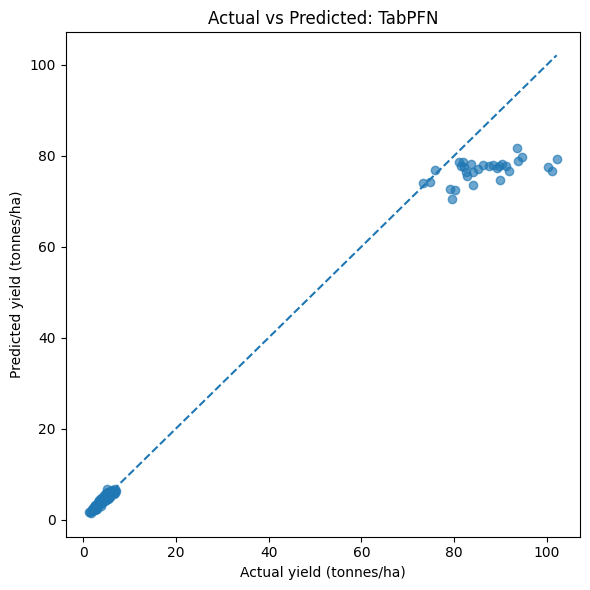


Completed models: ['TabFM', 'TabPFN']

IMPORTANT:
The dataset is labelled SYNTHETIC_FOR_PROTOTYPE. Metrics are only preliminary software tests, not real-world crop-yield evidence.
MSE, RMSE, MAE and R² are regression metrics. AUC is not appropriate for this continuous crop-yield target.


In [4]:

# ================================================================
# CROP YIELD PREDICTION: GOOGLE RESEARCH TABFM vs TABPFN
# Kaggle single-cell pipeline
# Install -> authenticate -> load data -> 80/20 split -> evaluate
# ================================================================

import os
import sys
import subprocess
import getpass
import traceback
import importlib
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. INSTALL / PREPARE PACKAGES
# ------------------------------------------------
print("=" * 65)
print("1. PREPARING PACKAGES")
print("=" * 65)

def pip_install(*args, cwd=None):
    cmd = [sys.executable, "-m", "pip", "install", *args]
    subprocess.check_call(cmd, cwd=cwd)

# Install TabPFN if needed
try:
    import tabpfn
    print("TabPFN package is installed.")
except Exception:
    pip_install("tabpfn")

# Install TabFM's missing core dependencies without replacing CUDA PyTorch.
pip_install(
    "absl-py",
    "jaxtyping<0.3",
    "typeguard<3",
    "huggingface-hub",
    "safetensors"
)

# Clone the official TabFM repository if needed
TABFM_REPO = "/kaggle/working/tabfm"

if not os.path.isfile(os.path.join(TABFM_REPO, "tabfm", "__init__.py")):
    if os.path.isdir(TABFM_REPO):
        import shutil
        shutil.rmtree(TABFM_REPO)

    subprocess.check_call([
        "git", "clone",
        "https://github.com/google-research/tabfm.git",
        TABFM_REPO
    ])

# Add the actual source repository to the front of Python's import path.
# This avoids accidentally importing a conflicting "tabfm" namespace.
sys.path.insert(0, TABFM_REPO)
importlib.invalidate_caches()

# Install the repository in editable mode without replacing PyTorch.
pip_install(
    "--no-deps", "-e", ".[pytorch]",
    cwd=TABFM_REPO
)

# ------------------------------------------------
# 2. IMPORTS AND GPU
# ------------------------------------------------
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("\nPyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        )
    )

# ------------------------------------------------
# 3. DATASET
# ------------------------------------------------
print("\n" + "=" * 65)
print("2. LOADING DATASET")
print("=" * 65)

TARGET = "crop_yield_tonnes_ha"

possible_paths = [
    "/kaggle/input/datasets/tasfiatahsinannitaan/"
    "sample-crop-yield-bd/bangladesh_crop_yield_synthetic_1000.csv",

    "/kaggle/input/datasets/tasfiatahsinannita/"
    "crop-yield-sample/bangladesh_crop_yield_synthetic_1000.csv",

    "/kaggle/input/crop-yield-sample/"
    "bangladesh_crop_yield_synthetic_1000.csv"
]

DATA_PATH = next(
    (p for p in possible_paths if os.path.isfile(p)),
    None
)

if DATA_PATH is None:
    found = list(
        Path("/kaggle/input").rglob(
            "bangladesh_crop_yield_synthetic_1000.csv"
        )
    )
    if not found:
        raise FileNotFoundError(
            "Cannot find bangladesh_crop_yield_synthetic_1000.csv "
            "under /kaggle/input. Attach the dataset to this notebook."
        )
    DATA_PATH = str(found[0])

df = pd.read_csv(DATA_PATH)

if TARGET not in df.columns:
    raise ValueError(f"Target {TARGET!r} not found in CSV.")

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

print("Dataset:", DATA_PATH)
print("Shape:", df.shape)
print("Target:", TARGET)

if "data_status" in df.columns:
    print("Data status:", df["data_status"].unique())

# Remove ID / metadata, not predictors
metadata_cols = [
    c for c in ["record_id", "country", "data_status"]
    if c in df.columns
]

X = df.drop(columns=[TARGET] + metadata_cols).copy()
y = df[TARGET].astype(float).copy()

numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [
    c for c in X.columns if c not in numeric_cols
]

for col in categorical_cols:
    X[col] = X[col].fillna("Unknown").astype(str)

print("Features:", X.shape[1])
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)

# ------------------------------------------------
# 4. 80/20 SPLIT AND IMPUTATION
# ------------------------------------------------
print("\n" + "=" * 65)
print("3. 80/20 TRAIN-TEST SPLIT")
print("=" * 65)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# Fit imputer on training data only
if numeric_cols:
    imputer = SimpleImputer(strategy="median")
    X_train.loc[:, numeric_cols] = imputer.fit_transform(
        X_train[numeric_cols]
    )
    X_test.loc[:, numeric_cols] = imputer.transform(
        X_test[numeric_cols]
    )

# TabPFN supports categorical columns in recent versions.
# Use string columns and let TabPFN detect categorical features.
X_train_pfn = X_train.copy()
X_test_pfn = X_test.copy()

# ------------------------------------------------
# 5. COMMON EVALUATION
# ------------------------------------------------
results = []
predictions_df = pd.DataFrame({
    "actual_yield_tonnes_ha": y_test.to_numpy()
})

def evaluate(name, predictions):
    predictions = np.asarray(predictions).reshape(-1).astype(float)

    if len(predictions) != len(y_test):
        raise ValueError("Prediction count does not match test rows.")
    if not np.isfinite(predictions).all():
        raise ValueError("Predictions contain non-finite values.")

    mse = mean_squared_error(y_test, predictions)
    rmse = float(np.sqrt(mse))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MSE": float(mse),
        "RMSE": rmse,
        "MAE": float(mae),
        "R2": float(r2)
    })

    predictions_df[name + "_prediction"] = predictions

    print(f"\n{name} metrics")
    print(f"MSE : {mse:.6f}")
    print(f"RMSE: {rmse:.6f} tonnes/ha")
    print(f"MAE : {mae:.6f} tonnes/ha")
    print(f"R²  : {r2:.6f}")

# ------------------------------------------------
# 6. TABFM
# ------------------------------------------------
print("\\n" + "=" * 65)
print("4. GOOGLE RESEARCH TABFM")
print("=" * 65)

try:
    # Clear a conflicting namespace import, if one was cached.
    cached = sys.modules.get("tabfm")
    if cached is not None and getattr(cached, "__file__", None) is None:
        for key in list(sys.modules):
            if key == "tabfm" or key.startswith("tabfm."):
                del sys.modules[key]
        importlib.invalidate_caches()

    from tabfm.src.classifier_and_regressor import TabFMRegressor
    from tabfm.src.pytorch import tabfm_v1_0_0 as tabfm_backend

    # Ensure inputs and targets are finite before calling the model.
    X_train_tabfm = X_train.copy()
    X_test_tabfm = X_test.copy()
    y_train_tabfm = np.asarray(y_train, dtype=np.float32).reshape(-1)

    for frame_name, frame in [
        ("X_train", X_train_tabfm),
        ("X_test", X_test_tabfm)
    ]:
        numeric_frame = frame.select_dtypes(include=["number"])
        if numeric_frame.size and not np.isfinite(
            numeric_frame.to_numpy(dtype=np.float64)
        ).all():
            raise ValueError(
                f"{frame_name} contains NaN or infinite numeric features "
                "after imputation."
            )
        for col in frame.select_dtypes(exclude=["number"]).columns:
            frame[col] = frame[col].fillna("Unknown").astype(str)

    if not np.isfinite(y_train_tabfm).all():
        raise ValueError("Training targets contain NaN or infinite values.")

    print("Loading pretrained TabFM regression checkpoint...")
    print("The first run may download several GB of model weights.")

    def load_tabfm_model(device, dtype=None):
        options = {"model_type": "regression", "device": device}
        if dtype is not None:
            options["dtype"] = dtype
        base = tabfm_backend.load(**options)
        reg = TabFMRegressor(
            model=base,
            max_num_rows=min(100, len(X_train_tabfm)),
            max_num_features=min(500, X_train_tabfm.shape[1])
        )
        return base, reg

    # First try GPU inference in FP16 to fit the Kaggle Tesla T4 memory limit.
    first_device = "cuda" if torch.cuda.is_available() else "cpu"
    first_dtype = torch.float16 if first_device == "cuda" else torch.float32

    tabfm_base, tabfm_model = load_tabfm_model(
        first_device, first_dtype
    )
    tabfm_model.fit(X_train_tabfm, y_train_tabfm)
    tabfm_pred = np.asarray(
        tabfm_model.predict(X_test_tabfm), dtype=np.float64
    ).reshape(-1)

    # FP16 can sometimes produce non-finite outputs. Retry on CPU in FP32
    # rather than replacing invalid predictions with zero or reporting metrics.
    if (
        len(tabfm_pred) != len(X_test_tabfm)
        or not np.isfinite(tabfm_pred).all()
    ):
        bad_count = (
            int((~np.isfinite(tabfm_pred)).sum())
            if len(tabfm_pred) == len(X_test_tabfm)
            else -1
        )
        print(
            f"Initial TabFM predictions were invalid (non-finite count: "
            f"{bad_count}). Retrying on CPU with float32."
        )

        del tabfm_model, tabfm_base
        import gc
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        tabfm_base, tabfm_model = load_tabfm_model("cpu", torch.float32)
        tabfm_model.fit(X_train_tabfm, y_train_tabfm)
        tabfm_pred = np.asarray(
            tabfm_model.predict(X_test_tabfm), dtype=np.float64
        ).reshape(-1)

    print("TabFM prediction count:", len(tabfm_pred))
    print("Finite TabFM predictions:", int(np.isfinite(tabfm_pred).sum()))
    print("Non-finite TabFM predictions:", int((~np.isfinite(tabfm_pred)).sum()))

    if len(tabfm_pred) != len(X_test_tabfm):
        raise ValueError(
            f"TabFM returned {len(tabfm_pred)} predictions for "
            f"{len(X_test_tabfm)} test rows."
        )
    if not np.isfinite(tabfm_pred).all():
        raise ValueError(
            "TabFM still returns NaN/inf after the CPU float32 retry. "
            "No TabFM metrics were recorded; inspect the model/runtime "
            "rather than replacing invalid predictions."
        )

    evaluate("TabFM", tabfm_pred)
    print("\\nTABFM SUCCESS")

except Exception as e:
    print("\\nTABFM FAILED:", type(e).__name__, str(e))
    traceback.print_exc(limit=6)
    print("Continuing to TabPFN.")

# ------------------------------------------------
# 7. TABPFN AUTHENTICATION AND MODEL
# ------------------------------------------------
print("\\n" + "=" * 65)
print("5. TABPFN")
print("=" * 65)

def get_tabpfn_token():
    # First try Kaggle Secrets, if configured.
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("TABPFN_TOKEN")
        if token:
            return token
    except Exception:
        pass

    # Then check an environment variable.
    token = os.environ.get("TABPFN_TOKEN")
    if token:
        return token

    # Prompt securely if running interactively.
    print(
        "\nTabPFN may require a license-accepted API token.\n"
        "Accept the model license at https://ux.priorlabs.ai,\n"
        "then get the token from https://ux.priorlabs.ai/account.\n"
        "You can also save it in Kaggle Secrets as TABPFN_TOKEN."
    )

    try:
        token = getpass.getpass(
            "Paste TabPFN API token (input hidden; Enter to skip): "
        ).strip()
    except Exception:
        token = ""

    return token or None

try:
    from tabpfn import TabPFNRegressor

    token = get_tabpfn_token()
    if token:
        os.environ["TABPFN_TOKEN"] = token

    print("Loading TabPFN regression model...")
    pfn_model = TabPFNRegressor(
        device="cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Fitting TabPFN and predicting test rows...")
    pfn_model.fit(X_train_pfn, y_train.to_numpy(dtype=np.float32))
    pfn_pred = pfn_model.predict(X_test_pfn)

    evaluate("TabPFN", pfn_pred)
    print("\nTABPFN SUCCESS")

except Exception as e:
    print("\nTABPFN FAILED:", type(e).__name__, str(e))
    traceback.print_exc(limit=4)

    if "license" in str(e).lower() or "token" in str(e).lower():
        print(
            "\nAction required: accept the TabPFN license and configure "
            "TABPFN_TOKEN in Kaggle Secrets, then rerun this cell."
        )

# ------------------------------------------------
# 8. RESULTS AND OUTPUT FILES
# ------------------------------------------------
print("\n" + "=" * 65)
print("6. MODEL COMPARISON")
print("=" * 65)

OUT_DIR = "/kaggle/working"

if results:
    results_df = pd.DataFrame(results).sort_values("RMSE")
    display(results_df)

    results_path = os.path.join(
        OUT_DIR, "model_comparison_results.csv"
    )
    predictions_path = os.path.join(
        OUT_DIR, "crop_yield_predictions.csv"
    )

    results_df.to_csv(results_path, index=False)
    predictions_df.to_csv(predictions_path, index=False)

    print("\nSaved:", results_path)
    print("Saved:", predictions_path)

    # RMSE comparison
    plt.figure(figsize=(7, 4))
    plt.bar(results_df["Model"], results_df["RMSE"])
    plt.ylabel("RMSE (tonnes/ha)")
    plt.title("TabFM vs TabPFN: RMSE")
    plt.tight_layout()
    plt.show()

    # MAE comparison
    plt.figure(figsize=(7, 4))
    plt.bar(results_df["Model"], results_df["MAE"])
    plt.ylabel("MAE (tonnes/ha)")
    plt.title("TabFM vs TabPFN: MAE")
    plt.tight_layout()
    plt.show()

    # Actual vs predicted
    for row in results:
        name = row["Model"]
        pred_col = name + "_prediction"

        if pred_col not in predictions_df:
            continue

        actual = predictions_df["actual_yield_tonnes_ha"]
        pred = predictions_df[pred_col]

        plt.figure(figsize=(6, 6))
        plt.scatter(actual, pred, alpha=0.65)

        low = min(actual.min(), pred.min())
        high = max(actual.max(), pred.max())
        plt.plot([low, high], [low, high], "--")

        plt.xlabel("Actual yield (tonnes/ha)")
        plt.ylabel("Predicted yield (tonnes/ha)")
        plt.title(f"Actual vs Predicted: {name}")
        plt.tight_layout()
        plt.show()

    print("\nCompleted models:", [r["Model"] for r in results])

else:
    print("No model completed successfully.")
    print(
        "This cell did not crash at the comparison stage. "
        "Use the specific model errors printed above to diagnose "
        "the remaining issue."
    )

print("\nIMPORTANT:")
print(
    "The dataset is labelled SYNTHETIC_FOR_PROTOTYPE. "
    "Metrics are only preliminary software tests, not real-world "
    "crop-yield evidence."
)
print(
    "MSE, RMSE, MAE and R² are regression metrics. AUC is not "
    "appropriate for this continuous crop-yield target."
)


1. CONFIGURATION AND DEPENDENCIES
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4

2. LOADING DATA
Dataset: /kaggle/input/datasets/tasfiatahsinannita/crop-yield-sample/bangladesh_crop_yield_synthetic_1000.csv
Shape: (1000, 18)
Synthetic dataset: True
Data status: ['SYNTHETIC_FOR_PROTOTYPE']

NOTICE: This dataset is synthetic. Results are software/model comparisons only, not evidence of real-world crop-yield accuracy.

3. FEATURE AND TARGET LEAKAGE AUDIT
No obvious target-derived columns detected by name.
Target: crop_yield_tonnes_ha
Feature count after exclusions: 14
Features: ['region', 'year', 'crop', 'season', 'rainfall_mm_season', 'avg_temperature_c', 'relative_humidity_pct', 'soil_ph', 'soil_moisture_m3_m3', 'solar_radiation_mj_m2_day', 'ndvi', 'fertilizer_kg_ha', 'irrigation_used_0_no_1_yes', 'previous_season_yield_tonnes_ha']
Numeric features: ['year', 'rainfall_mm_season', 'avg_temperature_c', 'relative_humidity_pct', 'soil_ph', 'soil_moisture_m3_m3', 'solar_radiation_

,Model,Runs,MSE_mean,MSE_std,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std
2,TabFM,5,6.53337,0.78442,2.55224,0.15597,1.07023,0.09619,0.99193,0.00150
1,Random Forest,5,7.42510,1.32136,2.71613,0.24424,1.11259,0.09510,0.99086,0.00186
0,DNN,5,14.17034,1.99563,3.75669,0.26836,2.03898,0.17759,0.98254,0.00294
3,TabPFN,5,16.44825,3.90286,4.03076,0.50157,1.48169,0.25455,0.98011,0.00325
4,XGBoost,5,25.50452,24.54189,4.59440,2.34415,1.34366,0.29180,0.96923,0.02894



All individual runs:


,Split,Seed,Train_rows,Test_rows,Model,MSE,RMSE,MAE,R2
0,Repeated random 80/20,42,800,200,TabFM,7.11320,2.66706,1.20954,0.99208
1,Repeated random 80/20,42,800,200,TabPFN,20.98277,4.58070,1.78080,0.97664
2,Repeated random 80/20,42,800,200,Random Forest,7.76145,2.78594,1.18156,0.99136
3,Repeated random 80/20,42,800,200,XGBoost,7.79408,2.79179,1.15411,0.99132
4,Repeated random 80/20,42,800,200,DNN,11.32021,3.36455,1.88791,0.98740
5,Repeated random 80/20,7,800,200,TabFM,7.26201,2.69481,1.07148,0.98955
6,Repeated random 80/20,7,800,200,TabPFN,10.53755,3.24616,1.09887,0.98483
7,Repeated random 80/20,7,800,200,Random Forest,7.48361,2.73562,1.03981,0.98923
8,Repeated random 80/20,7,800,200,XGBoost,8.24007,2.87055,1.03320,0.98814
9,Repeated random 80/20,7,800,200,DNN,13.40360,3.66109,1.93454,0.98071



Saved outputs to: /kaggle/working
- repeated_split_summary.csv
- all_model_evaluation_runs.csv
- all_model_predictions.csv


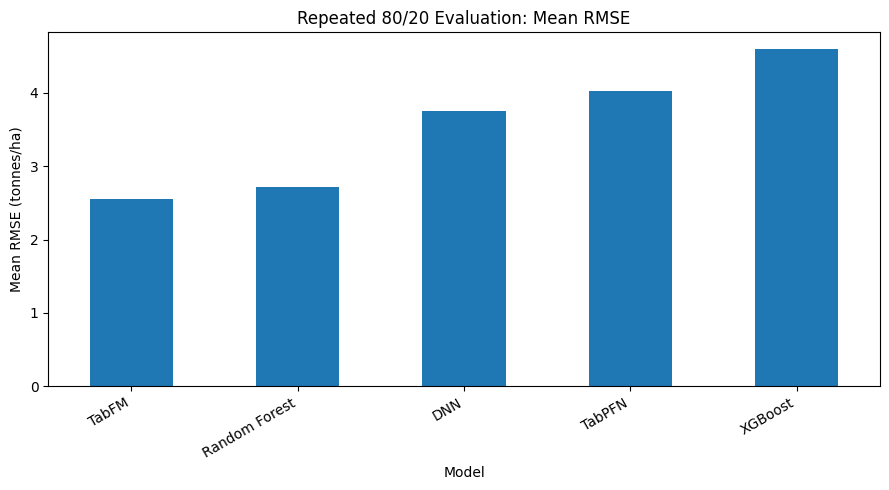

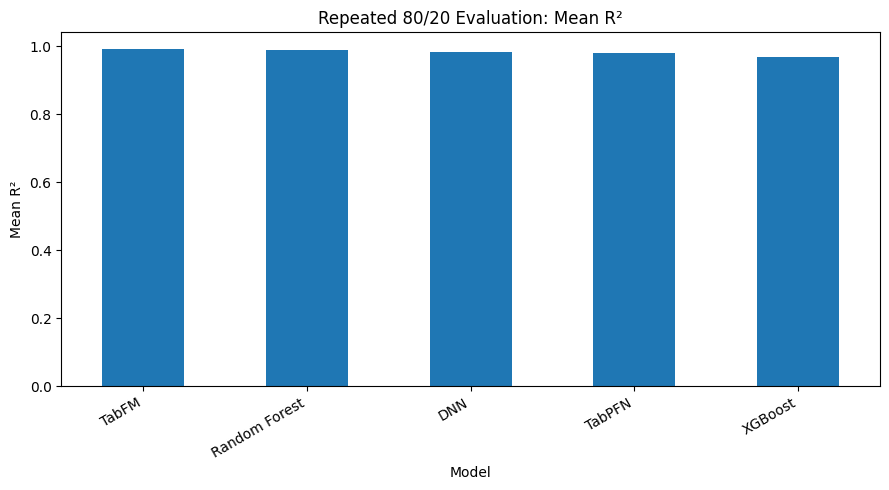


EVALUATION NOTES
1. All models use the same train/test indices within each split.
2. Preprocessing for conventional models is fitted on training rows only.
3. TabFM and TabPFN can fail independently; failed runs are reported.
4. Standard deviations across five seeds measure split sensitivity.
5. Synthetic-data results are not evidence of real-world accuracy.
6. For a real temporal test, set REAL_DATA_PATH to observed data.


In [5]:

# ================================================================
# CROP-YIELD RESEARCH VALIDATION CELL
# TabFM vs TabPFN vs Random Forest vs XGBoost vs DNN
# 1. Leakage audit
# 2. Five repeated 80/20 splits
# 3. Real-data / later-year evaluation when available
# 4. Mean, standard deviation, CSVs and plots
# ================================================================

import os
import sys
import subprocess
import importlib
import warnings
import traceback
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ------------------------------------------------
# CONFIGURATION
# ------------------------------------------------

TARGET = "crop_yield_tonnes_ha"

# Leave empty to use your current Kaggle dataset.
# To test real observed data, enter its CSV path here.
REAL_DATA_PATH = ""

RANDOM_SEEDS = [42, 7, 21, 32, 123]
TEST_SIZE = 0.20

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 75)
print("1. CONFIGURATION AND DEPENDENCIES")
print("=" * 75)

# XGBoost
try:
    from xgboost import XGBRegressor
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])
    from xgboost import XGBRegressor

# TabFM dependencies
for package, module in [
    ("jaxtyping<0.3", "jaxtyping"),
    ("typeguard<3", "typeguard")
]:
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", package
        ])

# Load official TabFM API
TABFM_REPO = "/kaggle/working/tabfm"
if os.path.isdir(TABFM_REPO):
    sys.path.insert(0, TABFM_REPO)

try:
    from tabfm.src.classifier_and_regressor import TabFMRegressor
    from tabfm.src.pytorch import tabfm_v1_0_0 as tabfm_backend
    TABFM_AVAILABLE = True
except Exception as e:
    TABFM_AVAILABLE = False
    print("TabFM import failed:", repr(e))

try:
    from tabpfn import TabPFNRegressor
    TABPFN_AVAILABLE = True
except Exception as e:
    TABPFN_AVAILABLE = False
    print("TabPFN import failed:", repr(e))

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------

print("\n" + "=" * 75)
print("2. LOADING DATA")
print("=" * 75)

default_paths = [
    "/kaggle/input/datasets/tasfiatahsinannita/crop-yield-sample/bangladesh_crop_yield_synthetic_1000.csv"
]

if REAL_DATA_PATH.strip():
    DATA_PATH = REAL_DATA_PATH.strip()
else:
    DATA_PATH = next(
        (p for p in default_paths if os.path.isfile(p)), None
    )
    if DATA_PATH is None:
        candidates = list(
            Path("/kaggle/input").rglob(
                "bangladesh_crop_yield_synthetic_1000.csv"
            )
        )
        if not candidates:
            raise FileNotFoundError(
                "Dataset not found. Set REAL_DATA_PATH to your CSV file."
            )
        DATA_PATH = str(candidates[0])

df = pd.read_csv(DATA_PATH)
if TARGET not in df.columns:
    raise ValueError(
        f"Target '{TARGET}' not found. Available columns: {df.columns.tolist()}"
    )

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

is_synthetic = (
    "synthetic" in DATA_PATH.lower()
    or (
        "data_status" in df.columns
        and df["data_status"].astype(str).str.contains(
            "SYNTHETIC", case=False, na=False
        ).any()
    )
)

print("Dataset:", DATA_PATH)
print("Shape:", df.shape)
print("Synthetic dataset:", is_synthetic)
if "data_status" in df.columns:
    print("Data status:", df["data_status"].unique())

if is_synthetic:
    print(
        "\nNOTICE: This dataset is synthetic. Results are software/model "
        "comparisons only, not evidence of real-world crop-yield accuracy."
    )

# ------------------------------------------------
# 3. FEATURE / TARGET LEAKAGE AUDIT
# ------------------------------------------------

print("\n" + "=" * 75)
print("3. FEATURE AND TARGET LEAKAGE AUDIT")
print("=" * 75)

metadata_cols = [
    c for c in ["record_id", "country", "data_status"]
    if c in df.columns
]

X_all = df.drop(columns=[TARGET] + metadata_cols).copy()
y_all = df[TARGET].astype(float).copy()

# Identify suspicious columns that may encode the current target.
# Previous-season / lagged yield is retained because it may be a valid
# predictor if it is genuinely known before the prediction date.
suspicious_cols = []
for col in X_all.columns:
    name = col.lower().replace("-", "_").replace(" ", "_")
    is_lagged = any(word in name for word in ["previous", "prev_", "lag"])
    looks_like_current_yield = (
        "yield" in name
        and not is_lagged
    )
    looks_like_target_copy = (
        name in ["target", "label", "y", "crop_yield_tonnes_ha"]
    )
    if looks_like_current_yield or looks_like_target_copy:
        suspicious_cols.append(col)

# Production / area can directly reconstruct yield when both refer to
# the same crop, region, and season. Remove them conservatively.
production_cols = [
    c for c in X_all.columns
    if "production" in c.lower()
]
area_cols = [
    c for c in X_all.columns
    if any(term in c.lower() for term in ["harvested_area", "area_harvested"])
]

if production_cols and area_cols:
    suspicious_cols.extend(production_cols + area_cols)

suspicious_cols = sorted(set(suspicious_cols))

if suspicious_cols:
    print("Potential target-leakage columns found and excluded:")
    for col in suspicious_cols:
        print(" -", col)
    X_all = X_all.drop(columns=suspicious_cols)
else:
    print("No obvious target-derived columns detected by name.")

print("Target:", TARGET)
print("Feature count after exclusions:", X_all.shape[1])
print("Features:", X_all.columns.tolist())

if X_all.shape[1] == 0:
    raise ValueError("No usable features remain after leakage checks.")

# Stable feature types used for every model and split.
numeric_cols = X_all.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [
    c for c in X_all.columns if c not in numeric_cols
]

# Make categorical values consistent for TabFM / TabPFN.
for col in categorical_cols:
    X_all[col] = X_all[col].where(X_all[col].notna(), "Unknown").astype(str)

# Check direct target copies and perfect numeric correlations.
# These are warnings for manual review, not proof of leakage by themselves.
for col in numeric_cols:
    values = pd.to_numeric(X_all[col], errors="coerce")
    valid = values.notna() & y_all.notna()
    if valid.sum() > 2:
        corr = values[valid].corr(y_all[valid])
        if pd.notna(corr) and abs(corr) > 0.9999:
            print(
                f"WARNING: {col!r} has near-perfect target correlation "
                f"({corr:.5f}). Inspect for leakage."
            )

print("Numeric features:", numeric_cols)
print("Categorical features:", categorical_cols)

# ------------------------------------------------
# 4. COMMON PREPROCESSING FOR CONVENTIONAL MODELS
# ------------------------------------------------

def make_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_cols),
        ("categorical", categorical_pipe, categorical_cols)
    ])

def prepare_tabular_data(X_train, X_test):
    """Fit imputers on training data only; apply to both partitions."""
    train = X_train.copy()
    test = X_test.copy()

    if numeric_cols:
        imputer = SimpleImputer(strategy="median")
        train.loc[:, numeric_cols] = imputer.fit_transform(train[numeric_cols])
        test.loc[:, numeric_cols] = imputer.transform(test[numeric_cols])

    for col in categorical_cols:
        train[col] = train[col].fillna("Unknown").astype(str)
        test[col] = test[col].fillna("Unknown").astype(str)

    return train, test

# ------------------------------------------------
# 5. METRICS AND MODEL RUNNERS
# ------------------------------------------------

def calculate_metrics(y_true, predictions):
    predictions = np.asarray(predictions, dtype=float).reshape(-1)
    y_true = np.asarray(y_true, dtype=float).reshape(-1)

    if len(predictions) != len(y_true):
        raise ValueError("Prediction count does not match test rows.")
    if not np.isfinite(predictions).all():
        raise ValueError("Predictions contain NaN or infinity.")
    if not np.isfinite(y_true).all():
        raise ValueError("Test targets contain NaN or infinity.")

    mse = mean_squared_error(y_true, predictions)
    return {
        "MSE": float(mse),
        "RMSE": float(np.sqrt(mse)),
        "MAE": float(mean_absolute_error(y_true, predictions)),
        "R2": float(r2_score(y_true, predictions))
    }

# Cache loaded TabFM checkpoints so repeated seeds don't redownload them.
tabfm_bases = {}

def get_tabfm_base(device):
    if device not in tabfm_bases:
        options = {"model_type": "regression", "device": device}
        if device == "cuda":
            options["dtype"] = torch.float16
        else:
            options["dtype"] = torch.float32
        tabfm_bases[device] = tabfm_backend.load(**options)
    return tabfm_bases[device]

def predict_tabfm(X_train, y_train, X_test):
    if not TABFM_AVAILABLE:
        raise RuntimeError("TabFM package is unavailable.")

    # First attempt GPU inference where available; retry on CPU if the
    # GPU produces invalid predictions or inference fails.
    devices = ["cuda", "cpu"] if torch.cuda.is_available() else ["cpu"]
    last_error = None

    for device in devices:
        try:
            base = get_tabfm_base(device)
            model = TabFMRegressor(
                model=base,
                max_num_rows=min(100, len(X_train)),
                max_num_features=min(500, X_train.shape[1])
            )
            model.fit(X_train, np.asarray(y_train, dtype=np.float32))
            pred = np.asarray(
                model.predict(X_test), dtype=float
            ).reshape(-1)

            if len(pred) != len(X_test) or not np.isfinite(pred).all():
                raise ValueError("TabFM returned non-finite predictions.")

            return pred
        except Exception as e:
            last_error = e
            print(f"TabFM {device} attempt failed: {type(e).__name__}: {e}")

    raise RuntimeError(f"TabFM failed on all available devices: {last_error}")

def predict_tabpfn(X_train, y_train, X_test):
    if not TABPFN_AVAILABLE:
        raise RuntimeError("TabPFN package is unavailable.")

    model = TabPFNRegressor(
        device="cuda" if torch.cuda.is_available() else "cpu"
    )
    model.fit(X_train, np.asarray(y_train, dtype=np.float32))
    return np.asarray(model.predict(X_test), dtype=float).reshape(-1)

def predict_random_forest(X_train, y_train, X_test, seed):
    preprocessor = make_preprocessor()
    model = Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=1,
            random_state=seed,
            n_jobs=-1
        ))
    ])
    model.fit(X_train, y_train)
    return model.predict(X_test)

def predict_xgboost(X_train, y_train, X_test, seed):
    model = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", XGBRegressor(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.04,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="reg:squarederror",
            random_state=seed,
            n_jobs=-1
        ))
    ])
    model.fit(X_train, y_train)
    return model.predict(X_test)

def predict_dnn(X_train, y_train, X_test, seed):
    model = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(128, 64),
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=400,
            early_stopping=True,
            random_state=seed
        ))
    ])
    model.fit(X_train, y_train)
    return model.predict(X_test)

# ------------------------------------------------
# 6. RUN ONE FAIR SPLIT
# ------------------------------------------------

all_results = []
prediction_records = []

def run_split(X, y, train_idx, test_idx, seed, split_name):
    X_train = X.iloc[train_idx].copy()
    X_test = X.iloc[test_idx].copy()
    y_train = y.iloc[train_idx].copy()
    y_test = y.iloc[test_idx].copy()

    X_train_model, X_test_model = prepare_tabular_data(X_train, X_test)

    print("\n" + "-" * 75)
    print(
        f"Split={split_name} | seed={seed} | "
        f"train={len(train_idx)} | test={len(test_idx)}"
    )
    print("Feature count:", X_train_model.shape[1])
    print("Train/test feature columns identical:",
          X_train_model.columns.tolist() == X_test_model.columns.tolist())
    print("Target:", TARGET)

    # Each model receives the same rows, same target and same input columns.
    runners = {
        "TabFM": lambda: predict_tabfm(
            X_train_model, y_train.to_numpy(), X_test_model
        ),
        "TabPFN": lambda: predict_tabpfn(
            X_train_model, y_train.to_numpy(), X_test_model
        ),
        "Random Forest": lambda: predict_random_forest(
            X_train, y_train, X_test, seed
        ),
        "XGBoost": lambda: predict_xgboost(
            X_train, y_train, X_test, seed
        ),
        "DNN": lambda: predict_dnn(
            X_train, y_train, X_test, seed
        )
    }

    for model_name, runner in runners.items():
        try:
            print(f"\nRunning {model_name}...")
            pred = runner()
            metrics = calculate_metrics(y_test.to_numpy(), pred)

            row = {
                "Split": split_name,
                "Seed": seed,
                "Train_rows": len(train_idx),
                "Test_rows": len(test_idx),
                "Model": model_name,
                **metrics
            }
            all_results.append(row)

            for i, prediction in enumerate(pred):
                prediction_records.append({
                    "Split": split_name,
                    "Seed": seed,
                    "Model": model_name,
                    "row_index": int(test_idx[i]),
                    "actual_yield_tonnes_ha": float(y_test.iloc[i]),
                    "predicted_yield_tonnes_ha": float(prediction)
                })

            print(
                f"RMSE={metrics['RMSE']:.4f} | "
                f"MAE={metrics['MAE']:.4f} | R2={metrics['R2']:.4f}"
            )
        except Exception as e:
            print(f"{model_name} FAILED: {type(e).__name__}: {e}")
            traceback.print_exc(limit=2)

# ------------------------------------------------
# 7. REPEATED RANDOM 80/20 SPLITS
# ------------------------------------------------

print("\n" + "=" * 75)
print("4. REPEATED 80/20 EVALUATION")
print("=" * 75)

indices = np.arange(len(X_all))

for seed in RANDOM_SEEDS:
    train_idx, test_idx = train_test_split(
        indices,
        test_size=TEST_SIZE,
        random_state=seed
    )

    # Confirm each model uses exactly this split.
    assert len(train_idx) + len(test_idx) == len(X_all)
    run_split(
        X_all, y_all,
        train_idx, test_idx,
        seed=seed,
        split_name="Repeated random 80/20"
    )

# ------------------------------------------------
# 8. LATER-YEAR HOLDOUT FOR REAL OBSERVED DATA
# ------------------------------------------------

print("\n" + "=" * 75)
print("5. LATER-YEAR HOLDOUT")
print("=" * 75)

if is_synthetic:
    print(
        "SKIPPED: Current dataset is synthetic. Use a real observed dataset "
        "before interpreting a year-based holdout as crop-yield forecasting."
    )
elif "year" not in df.columns:
    print(
        "SKIPPED: No 'year' column found. Add or map the observation year "
        "before running a temporal holdout."
    )
else:
    year_values = pd.to_numeric(df["year"], errors="coerce")
    valid_year = year_values.notna()
    years = sorted(year_values[valid_year].unique())

    if len(years) < 2:
        print("SKIPPED: Need at least two distinct years.")
    else:
        latest_year = years[-1]
        train_idx = np.where((year_values < latest_year) & valid_year)[0]
        test_idx = np.where((year_values == latest_year) & valid_year)[0]

        if len(train_idx) < 20 or len(test_idx) < 5:
            print(
                "SKIPPED: Too few rows before the latest year or in the "
                "latest-year test set."
            )
        else:
            print("Training years:", years[:-1])
            print("Held-out test year:", latest_year)
            run_split(
                X_all, y_all,
                train_idx, test_idx,
                seed=0,
                split_name=f"Temporal holdout ({latest_year})"
            )

# ------------------------------------------------
# 9. SUMMARY: MEAN AND STANDARD DEVIATION
# ------------------------------------------------

print("\n" + "=" * 75)
print("6. RESULTS SUMMARY")
print("=" * 75)

results_df = pd.DataFrame(all_results)

if results_df.empty:
    print("No models completed successfully. Review the errors above.")
else:
    random_results = results_df[
        results_df["Split"] == "Repeated random 80/20"
    ].copy()

    if not random_results.empty:
        summary = random_results.groupby("Model").agg(
            Runs=("Seed", "count"),
            MSE_mean=("MSE", "mean"),
            MSE_std=("MSE", "std"),
            RMSE_mean=("RMSE", "mean"),
            RMSE_std=("RMSE", "std"),
            MAE_mean=("MAE", "mean"),
            MAE_std=("MAE", "std"),
            R2_mean=("R2", "mean"),
            R2_std=("R2", "std")
        ).reset_index()

        summary = summary.sort_values("RMSE_mean")
        print("\nRepeated random split summary (mean and standard deviation):")
        display(summary.round(5))

        summary.to_csv(
            os.path.join(OUTPUT_DIR, "repeated_split_summary.csv"),
            index=False
        )

    print("\nAll individual runs:")
    display(results_df.round(5))

    results_df.to_csv(
        os.path.join(OUTPUT_DIR, "all_model_evaluation_runs.csv"),
        index=False
    )

    if prediction_records:
        pd.DataFrame(prediction_records).to_csv(
            os.path.join(OUTPUT_DIR, "all_model_predictions.csv"),
            index=False
        )

    print("\nSaved outputs to:", OUTPUT_DIR)
    print("- repeated_split_summary.csv")
    print("- all_model_evaluation_runs.csv")
    print("- all_model_predictions.csv")

    # Plot mean RMSE across repeated random splits.
    if not random_results.empty:
        rmse_plot = random_results.groupby("Model")["RMSE"].mean().sort_values()
        plt.figure(figsize=(9, 5))
        rmse_plot.plot(kind="bar")
        plt.ylabel("Mean RMSE (tonnes/ha)")
        plt.title("Repeated 80/20 Evaluation: Mean RMSE")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

        # Plot mean R²
        r2_plot = random_results.groupby("Model")["R2"].mean().sort_values(
            ascending=False
        )
        plt.figure(figsize=(9, 5))
        r2_plot.plot(kind="bar")
        plt.ylabel("Mean R²")
        plt.title("Repeated 80/20 Evaluation: Mean R²")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

print("\n" + "=" * 75)
print("EVALUATION NOTES")
print("=" * 75)
print("1. All models use the same train/test indices within each split.")
print("2. Preprocessing for conventional models is fitted on training rows only.")
print("3. TabFM and TabPFN can fail independently; failed runs are reported.")
print("4. Standard deviations across five seeds measure split sensitivity.")
print("5. Synthetic-data results are not evidence of real-world accuracy.")
print("6. For a real temporal test, set REAL_DATA_PATH to observed data.")
